design a $20\text{ kW}$, $3$-phase ($3\phi$), $415\text{ V}$, $50\text{ Hz}$ ($f = 50\text{ Hz}$), $1500\text{ rpm}$ synchronous speed squirrel-cage induction motor at full load, operating with an efficiency ($\eta$) of $86\%$ ($0.86$) and a power factor ($\cos\phi$) of $0.85$, such that the temperature rise does not exceed $50^\circ\text{C}$. For the electromagnetic design calculations, assume a specific magnetic loading ($B_{\text{avg}}$) of $0.45\text{ T}$, a specific electric loading ($q$) of $25,000\text{ A/m}$, and a winding factor ($k_w$) of $0.955$.

In [ ]:
import math
import femm
import time

MAXSEG = 1   # max degrees per arc mesh segment (must be > 0)

def create_complete_motor_design():
    # ------------------------------------------------------------------
    # 1. Initialize FEMM in 2D Planar mode
    # ------------------------------------------------------------------
    femm.openfemm()
    femm.newdocument(0)  # 0 = Magnetics problem
    femm.mi_probdef(50, 'millimeters', 'planar', 1e-8, 210, 30)

    # ------------------------------------------------------------------
    # 2. Materials
    # mi_addmaterial(name, mu_x, mu_y, H_c, J, Cduct[MS/m], Lam_d[mm],
    #                Phi_hmax, lam_fill, LamType, Phi_hx, Phi_hy)
    # ------------------------------------------------------------------
    femm.mi_addmaterial('Air',        1,    1,    0, 0, 0,    0,   0, 1,    0, 0, 0)
    # Laminated steel: no bulk conductivity, 0.5 mm laminations, 95% fill
    femm.mi_addmaterial('M-19 Steel', 1800, 1800, 0, 0, 0,    0.5, 0, 0.95, 0, 0, 0)
    femm.mi_addmaterial('Copper',     1,    1,    0, 0, 58,   0,   0, 1,    0, 0, 0)
    femm.mi_addmaterial('Aluminum',   1,    1,    0, 0, 37.7, 0,   0, 1,    0, 0, 0)

    # ------------------------------------------------------------------
    # 3. Boundary condition
    # ------------------------------------------------------------------
    femm.mi_addboundprop('ZeroFlux', 0, 0, 0, 0, 0, 0, 0, 0, 0)

    # ------------------------------------------------------------------
    # 4. 3-Phase Circuits
    # ------------------------------------------------------------------
    peak_current = 53.8
    femm.mi_addcircprop('PhaseA',  peak_current,        1)
    femm.mi_addcircprop('PhaseB', -peak_current / 2.0, 1)
    femm.mi_addcircprop('PhaseC', -peak_current / 2.0, 1)

    # ------------------------------------------------------------------
    # 5. Geometry (mm)
    # ------------------------------------------------------------------
    r_shaft         = 35.0
    r_rotor_outer   = 104.5
    r_stator_inner  = 105.0
    r_stator_outer  = 170.0
    r_air_outer     = 250.0

    def draw_full_circle(r, group_id=0, bound_name='None'):
        segments = 72
        for i in range(segments):
            t1 = 2 * math.pi * i / segments
            t2 = 2 * math.pi * (i + 1) / segments
            x1, y1 = r * math.cos(t1), r * math.sin(t1)
            x2, y2 = r * math.cos(t2), r * math.sin(t2)
            femm.mi_addnode(x1, y1)
            femm.mi_addnode(x2, y2)
            femm.mi_addarc(x1, y1, x2, y2, 360.0 / segments, MAXSEG)

            if bound_name != 'None':
                # apply boundary condition to this arc (select by midpoint)
                tm = 0.5 * (t1 + t2)
                femm.mi_clearselected()
                femm.mi_selectarcsegment(r * math.cos(tm), r * math.sin(tm))
                femm.mi_setarcsegmentprop(MAXSEG, bound_name, 0, 0)
                femm.mi_clearselected()

    def label(x, y, material, circuit='<None>', turns=0):
        femm.mi_addblocklabel(x, y)
        femm.mi_selectlabel(x, y)
        # (block, automesh, meshsize, incircuit, magdir, group, turns)
        femm.mi_setblockprop(material, 1, 0, circuit, 0, 0, turns)
        femm.mi_clearselected()

    # ------------------------------------------------------------------
    # 6. Shaft, rotor outer surface, stator outer surface, air boundary
    # ------------------------------------------------------------------
    draw_full_circle(r_shaft, group_id=1)
    draw_full_circle(r_rotor_outer, group_id=2)          # FIX: was missing
    draw_full_circle(r_stator_outer, group_id=4)
    draw_full_circle(r_air_outer, group_id=99, bound_name='ZeroFlux')

    # FIX: shaft interior had no label
    label(0, 0, 'M-19 Steel')

    # ------------------------------------------------------------------
    # 7. Stator slots (36) with 4-pole, 3-phase winding
    # ------------------------------------------------------------------
    num_stator_slots = 36
    slot_depth_s     = 15.0
    slot_pitch       = 2 * math.pi / num_stator_slots
    slot_half_angle  = 0.30 * slot_pitch

    # 3 slots per group; 4-pole sequence: A+ C- B+ A- C+ B-  (repeats)
    winding = [('PhaseA', 1), ('PhaseC', -1), ('PhaseB', 1),
               ('PhaseA', -1), ('PhaseC', 1), ('PhaseB', -1)]

    for i in range(num_stator_slots):
        theta_c = i * slot_pitch
        theta_l = theta_c - slot_half_angle
        theta_r = theta_c + slot_half_angle

        r_in  = r_stator_inner
        r_out = r_stator_inner + slot_depth_s

        p_in_l  = (r_in  * math.cos(theta_l), r_in  * math.sin(theta_l))
        p_in_r  = (r_in  * math.cos(theta_r), r_in  * math.sin(theta_r))
        p_out_l = (r_out * math.cos(theta_l), r_out * math.sin(theta_l))
        p_out_r = (r_out * math.cos(theta_r), r_out * math.sin(theta_r))

        for p in (p_in_l, p_in_r, p_out_l, p_out_r):
            femm.mi_addnode(p[0], p[1])

        arc_deg = math.degrees(slot_half_angle * 2)
        femm.mi_addarc(p_in_l[0],  p_in_l[1],  p_in_r[0],  p_in_r[1],  arc_deg, MAXSEG)
        femm.mi_addsegment(p_in_l[0], p_in_l[1], p_out_l[0], p_out_l[1])
        # FIX: angle must be positive (left -> right is counter-clockwise)
        femm.mi_addarc(p_out_l[0], p_out_l[1], p_out_r[0], p_out_r[1], arc_deg, MAXSEG)
        femm.mi_addsegment(p_out_r[0], p_out_r[1], p_in_r[0], p_in_r[1])

        # Tooth-tip arc to next slot opening (wraps around on last slot)
        next_theta_l = (i + 1) * slot_pitch - slot_half_angle
        np_x, np_y = r_in * math.cos(next_theta_l), r_in * math.sin(next_theta_l)
        femm.mi_addnode(np_x, np_y)
        femm.mi_addarc(p_in_r[0], p_in_r[1], np_x, np_y,
                       math.degrees(next_theta_l - theta_r), MAXSEG)

        # Copper label
        r_mid = 0.5 * (r_in + r_out)
        phase, sign = winding[(i // 3) % 6]
        label(r_mid * math.cos(theta_c), r_mid * math.sin(theta_c),
              'Copper', phase, sign)

    # Stator core label (angle 5 deg = tooth centre, never inside a slot)
    r_stator_core = 0.5 * (r_stator_inner + slot_depth_s + r_stator_outer)
    a = slot_pitch / 2
    label(r_stator_core * math.cos(a), r_stator_core * math.sin(a), 'M-19 Steel')

    # ------------------------------------------------------------------
    # 8. Rotor bars (28)
    # ------------------------------------------------------------------
    num_rotor_slots = 28
    bar_depth       = 8.0
    rotor_pitch     = 2 * math.pi / num_rotor_slots
    bar_width_ang   = 0.45 * rotor_pitch
    r_bar_out       = r_rotor_outer - 2.0
    r_bar_in        = r_bar_out - bar_depth

    for i in range(num_rotor_slots):
        theta_c = i * rotor_pitch
        theta_l = theta_c - bar_width_ang
        theta_r = theta_c + bar_width_ang

        p_in_l  = (r_bar_in  * math.cos(theta_l), r_bar_in  * math.sin(theta_l))
        p_in_r  = (r_bar_in  * math.cos(theta_r), r_bar_in  * math.sin(theta_r))
        p_out_l = (r_bar_out * math.cos(theta_l), r_bar_out * math.sin(theta_l))
        p_out_r = (r_bar_out * math.cos(theta_r), r_bar_out * math.sin(theta_r))

        for p in (p_in_l, p_in_r, p_out_l, p_out_r):
            femm.mi_addnode(p[0], p[1])

        arc_deg = math.degrees(bar_width_ang * 2)
        femm.mi_addarc(p_in_l[0],  p_in_l[1],  p_in_r[0],  p_in_r[1],  arc_deg, MAXSEG)
        femm.mi_addsegment(p_in_l[0], p_in_l[1], p_out_l[0], p_out_l[1])
        # FIX: positive angle
        femm.mi_addarc(p_out_l[0], p_out_l[1], p_out_r[0], p_out_r[1], arc_deg, MAXSEG)
        femm.mi_addsegment(p_out_r[0], p_out_r[1], p_in_r[0], p_in_r[1])

        r_mid = 0.5 * (r_bar_in + r_bar_out)
        label(r_mid * math.cos(theta_c), r_mid * math.sin(theta_c), 'Aluminum')

    # Rotor core label (between two bars, between shaft and bars)
    r_rc = 0.5 * (r_shaft + r_bar_in)
    th = 0.5 * rotor_pitch
    label(r_rc * math.cos(th), r_rc * math.sin(th), 'M-19 Steel')

    # ------------------------------------------------------------------
    # 9. Air gap & outer air
    # ------------------------------------------------------------------
    r_gap = 0.5 * (r_rotor_outer + r_stator_inner)
    label(r_gap * math.cos(th), r_gap * math.sin(th), 'Air')

    r_outer_air = 0.5 * (r_stator_outer + r_air_outer)
    label(r_outer_air, 0, 'Air')

    # ------------------------------------------------------------------
    # 10. Save, mesh, solve
    # ------------------------------------------------------------------
    femm.mi_saveas('motor_20kw_fully_excited.fem')
    print('Model saved successfully. Generating mesh...')
    femm.mi_createmesh()
    time.sleep(0.5)

    print('Running FEA solver...')
    femm.mi_analyze(1)
    femm.mi_loadsolution()
    print('Solution loaded successfully in FEMM!')

if __name__ == '__main__':
    create_complete_motor_design()


simulation o/p;

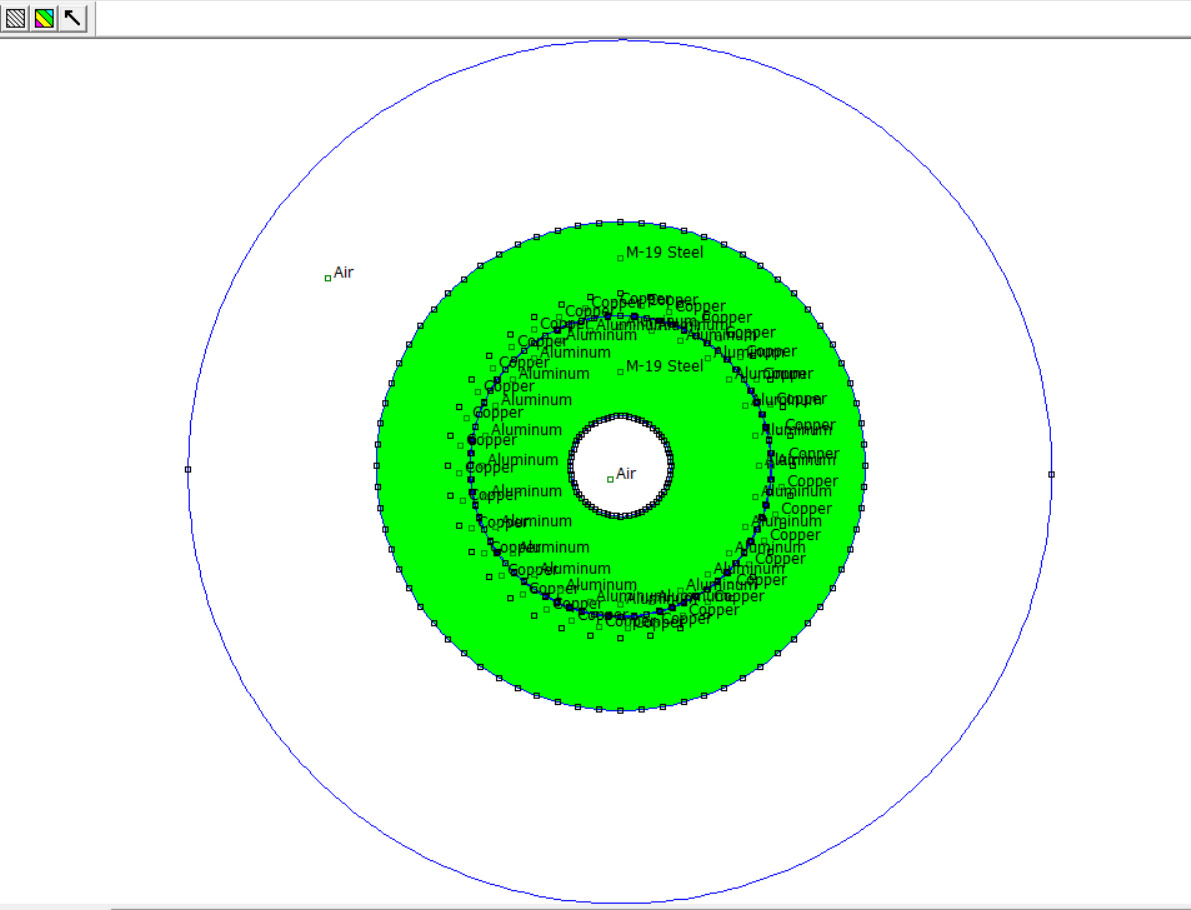

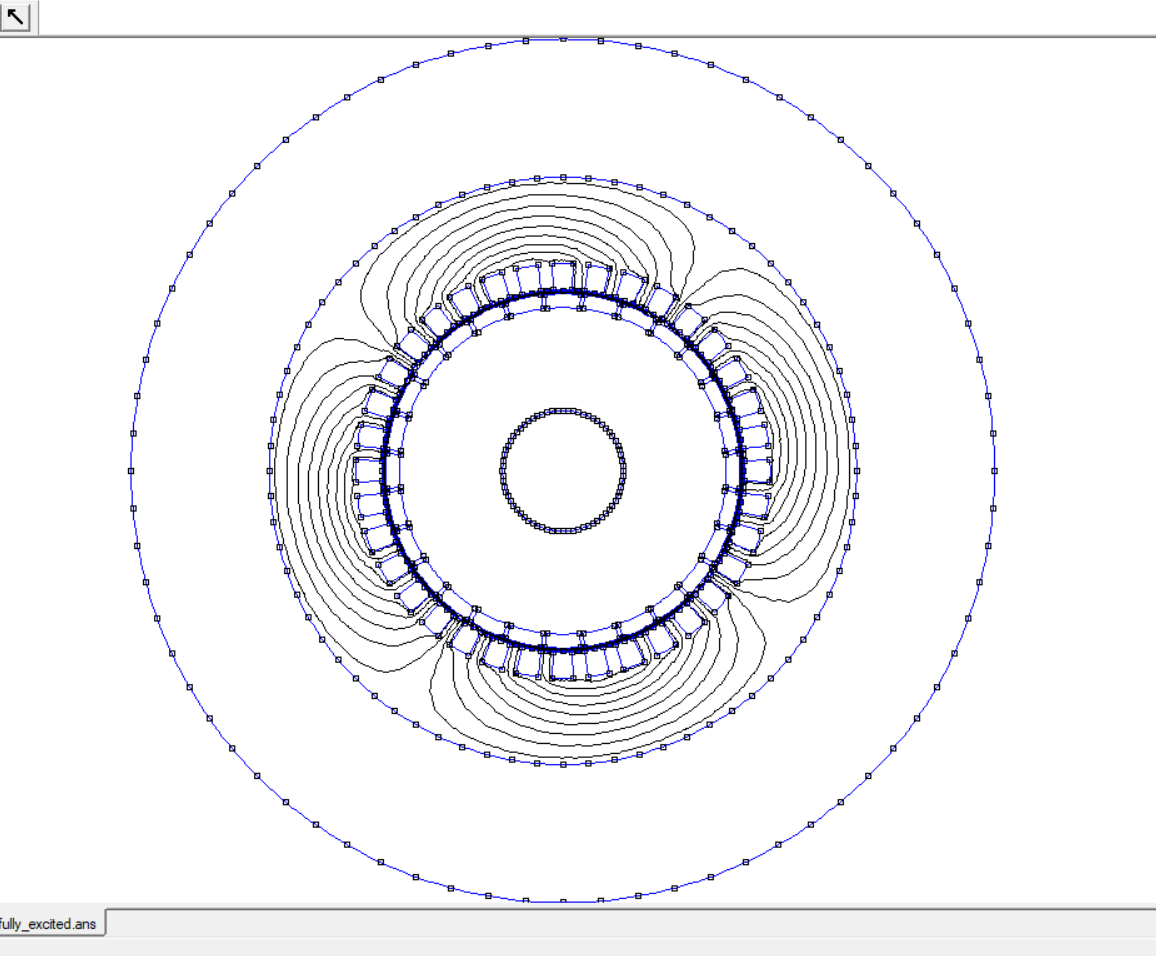

In [1]:
import os
from IPython.display import Image, display, HTML

# 1. Grab all 4 absolute paths cleanly
p1 = os.path.abspath("../img/Screenshot 2026-11-01 180322.png")
p2 = os.path.abspath("../img/Screenshot 2026-11-01 180612.png")

# 2. Tell Jupyter to display them inline side-by-side using minimal CSS styling
display(HTML("<style>.output_subarea { display: flex; flex-wrap: wrap; }</style>"))
display(Image(filename=p1, width=350), Image(filename=p2, width=350))